## The Curse of Dimensionality

Humans are bound by their perception of a maximum of three dimensions. We can’t comprehend shapes/graphs beyond three dimensions. Often, data scientists get datasets which have thousands of features. They give birth to two kinds of problems:

* **Increase in computation time:** Majority of the machine learning algorithms they rely on the calculation of distance for model building and as the number of dimensions increases it becomes more and more computation-intensive to create a model out of it. For example, if we have to calculate the distance between two points in just one dimension, like two points on the number line, we’ll just subtract the coordinate of one point from another and then take the magnitude:

Distance= $ x_1-x_2 $

What if we need to calculate the distance between two points in two dimensions?

The same formula translates to:
Distance= $ \sqrt {(x_1-x_2)^2+(y_1-y_2)^2} $

What if we need to calculate the distance between two points in three dimensions?

The same formula translates to:
Distance= $ \sqrt {(x_1-x_2)^2+(y_1-y_2)^2+(z_1-z_2)^2}$

And for N-dimensions, the formula becomes:
Distance=$ \sqrt {(a_1-a_2)^2+(b_1-b_2)^2+(c_1-c_2)^2+…+(n_1-n_2)^2} $

This is the effort of calculating the distance between two points. Just imagine the number of calculations involved for all the data points involved.

One more point to consider is that as the number of dimension increases, points are going far away from each other. This means that any new point that comes when we are testing the model is going to be farther away from our training points. This leads to a less reliable model, and it makes our model overfitted to the training data.



* **Hard (or almost impossible) to visualise the relationship between features:** As stated above, humans can not comprehend things beyond three dimensions. So, if we have an n-dimensional dataset, the only solution left to us is to create either a 2-D or 3-D graph out of it. Let’s say for simplicity, we are creating 2-D graphs. Suppose we have 1000 features in the dataset. That results in a  total (1000*999)/2= 499500 combinations possible for creating the 2-D graph.

Is it humanly possible to analyse all those graphs to understand the relationship between the variables?

**The questions that we need to ask at this point are:**

* Are all the features really contributing to decision making?
* Is there a way to come to the same conclusion using a lesser number of features?
* Is there a way to combine features to create a new feature and drop the old ones?
* Is there a way to remodel features in a way to make them visually comprehensible?

The answer to all the above questions is- _Dimensionality Reduction technique._




## Principal Component Analysis: 
The principal component analysis is an unsupervised machine learning algorithm used for feature selection using dimensionality reduction techniques. As the name suggests, it finds out the principal components from the data. PCA transforms and fits the data from a higher-dimensional space to a new, lower-dimensional subspace This results into an entirely new coordinate system of the points where the first axis corresponds to the first principal component that explains the most variance in the data.

**What are the principal components?**
Principal components are the derived features which explain the maximum variance in the data. The first principal component explains the most variance, the 2nd a bit less and so on. Each of the new dimensions found using PCA is a linear combination of the old features.

Let's take the following example where the data is distributed like the diagram on the left:
<img src="PCA_intro1.PNG" width="500">



**what is the optimum number of Principal components needed?**


#### Explained Variance Ratio

All of the above questions are answered using the *explained variance ratio*. It represents the amount of variance each principal component is able to explain.

For example, suppose if the square of distances of all the points from the origin that lie on PC1 is 50 and for the points on PC2 it’s 5.

EVR of PC1=$\frac{Distance of PC1 points}{( Distance of PC1 points+ Distance of PC2 points)}=\frac{50}{55}=0.91 $

EVR of PC2=$\frac{Distance of PC2 points}{( Distance of PC1 points+ Distance of PC2 points)}=\frac{5}{55}=0.09 $


Thus PC1 explains 91% of the variance of data. Whereas, PC2 only explains 9% of the variance. Hence we can use only PC1 as the input for our model as it explains the majority of the variance.

In a real-life scenario, this problem is solved using the **Scree Plots**

## Scree Plots:
Scree plots are the graphs that convey how much variance is explained by corresponding Principal components. 
<img src="scree.PNG" width="500">

As shown in the given diagram, around 75 principal components explain approximately 90 % of the variance. Hence, 75 can be a good choice based on the scenario

In [4]:
# importing important labries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# So, Basically we are going to use inbuilt dataset from seaborn
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

#### Load the real `brain_networks`

This CSV has a **three-level column header** describing network, node, and hemisphere. The official Seaborn loading pattern preserves those header levels and uses the first column as the row index

In [24]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/brain_networks.csv"
data = pd.read_csv(url, header=[0, 1, 2], index_col=0)

In [27]:
data.head()

network          1                     2                     3             \
node             1                     1                     1              
hemi            lh         rh         lh         rh         lh         rh   
0        56.055744  92.031036   3.391576  38.659683  26.203819 -49.715569   
1        55.547253  43.690075 -65.495987 -13.974523 -28.274963 -39.050129   
2        60.997768  63.438793 -51.108582 -13.561346 -18.842947  -1.214659   
3        18.514868  12.657158 -34.576603 -32.665958  -7.420454  17.119448   
4        -2.527392 -63.104668 -13.814151 -15.837989 -45.216927   3.483550   

network          4                     5             ...         16  \
node             1                     1             ...          3   
hemi            lh         rh         lh         rh  ...         rh   
0        47.461037  26.746613 -35.898861  -1.889181  ...   0.607904   
1        -1.210660 -19.012897  19.568010  15.902983  ...  57.495071   
2       -65.575806 -85.777428  19.247454  37.209419  ...  28.317369   
3       -41.800869 -58.610184  32.896915  11.199619  ...  71.439629   
4       -62.613335 -49.076508  18.396759   3.219077  ...  95.597565   

network                                17                                   \
node             4                      1                     2              
hemi            lh          rh         lh         rh         lh         rh   
0       -70.270546   77.365776 -21.734550   1.028253   7.791784  68.903725   
1       -76.393219  127.261360 -13.035799  46.381824 -15.752450  31.000332   
2         9.063977   45.493263  26.033442  34.212200   1.326110 -22.580757   
3        65.842979  -10.697547  55.297466   4.255006  -2.420144  12.098393   
4        50.960453  -23.197300  43.067562  52.219875  28.232882 -11.719750   

network                                    
node             3                      4  
hemi            lh          rh         lh  
0       -10.520872  120.490463 -39.686432  
1       -39.607521   24.764011 -36.771008  
2        12.985169  -75.027451   6.434262  
3       -15.819172  -37.361431  -4.650954  
4         5.453649    5.169828  87.809135  

[5 rows x 62 columns]

In [31]:
# here we are loading Brain Networks datasets
df = data

In [33]:
df.head()

network          1                     2                     3             \
node             1                     1                     1              
hemi            lh         rh         lh         rh         lh         rh   
0        56.055744  92.031036   3.391576  38.659683  26.203819 -49.715569   
1        55.547253  43.690075 -65.495987 -13.974523 -28.274963 -39.050129   
2        60.997768  63.438793 -51.108582 -13.561346 -18.842947  -1.214659   
3        18.514868  12.657158 -34.576603 -32.665958  -7.420454  17.119448   
4        -2.527392 -63.104668 -13.814151 -15.837989 -45.216927   3.483550   

network          4                     5             ...         16  \
node             1                     1             ...          3   
hemi            lh         rh         lh         rh  ...         rh   
0        47.461037  26.746613 -35.898861  -1.889181  ...   0.607904   
1        -1.210660 -19.012897  19.568010  15.902983  ...  57.495071   
2       -65.575806 -85.777428  19.247454  37.209419  ...  28.317369   
3       -41.800869 -58.610184  32.896915  11.199619  ...  71.439629   
4       -62.613335 -49.076508  18.396759   3.219077  ...  95.597565   

network                                17                                   \
node             4                      1                     2              
hemi            lh          rh         lh         rh         lh         rh   
0       -70.270546   77.365776 -21.734550   1.028253   7.791784  68.903725   
1       -76.393219  127.261360 -13.035799  46.381824 -15.752450  31.000332   
2         9.063977   45.493263  26.033442  34.212200   1.326110 -22.580757   
3        65.842979  -10.697547  55.297466   4.255006  -2.420144  12.098393   
4        50.960453  -23.197300  43.067562  52.219875  28.232882 -11.719750   

network                                    
node             3                      4  
hemi            lh          rh         lh  
0       -10.520872  120.490463 -39.686432  
1       -39.607521   24.764011 -36.771008  
2        12.985169  -75.027451   6.434262  
3       -15.819172  -37.361431  -4.650954  
4         5.453649    5.169828  87.809135  

[5 rows x 62 columns]

In [35]:
# here we are resting the index of our data
df.reset_index(drop=True, inplace=True)

In [37]:
df

network           1                     2                     3             \
node              1                     1                     1              
hemi             lh         rh         lh         rh         lh         rh   
0         56.055744  92.031036   3.391576  38.659683  26.203819 -49.715569   
1         55.547253  43.690075 -65.495987 -13.974523 -28.274963 -39.050129   
2         60.997768  63.438793 -51.108582 -13.561346 -18.842947  -1.214659   
3         18.514868  12.657158 -34.576603 -32.665958  -7.420454  17.119448   
4         -2.527392 -63.104668 -13.814151 -15.837989 -45.216927   3.483550   
..              ...        ...        ...        ...        ...        ...   
915       -7.429513  -4.813219  -3.670537   1.442261 -19.680431 -29.109356   
916      -33.554138 -38.605621 -25.664803 -30.252352   5.562785  20.182186   
917      -78.539566 -74.197189 -54.041595 -39.970291 -14.277059 -30.606461   
918     -103.235825 -98.744286 -40.109543 -44.907734  12.109148   1.621340   
919      -36.288868 -10.762070 -30.356262 -23.319504  14.252188 -27.559860   

network          4                     5             ...          16  \
node             1                     1             ...           3   
hemi            lh         rh         lh         rh  ...          rh   
0        47.461037  26.746613 -35.898861  -1.889181  ...    0.607904   
1        -1.210660 -19.012897  19.568010  15.902983  ...   57.495071   
2       -65.575806 -85.777428  19.247454  37.209419  ...   28.317369   
3       -41.800869 -58.610184  32.896915  11.199619  ...   71.439629   
4       -62.613335 -49.076508  18.396759   3.219077  ...   95.597565   
..             ...        ...        ...        ...  ...         ...   
915      -3.376562  -8.764893   0.017912 -25.305094  ...   58.285793   
916      17.911247  24.653582 -32.935612 -21.783203  ...   59.864819   
917      60.628521  62.027023 -32.800556 -37.021500  ...   68.767868   
918      33.765560  55.356071 -14.330512 -17.224781  ...  103.155251   
919      17.279512 -19.060152  26.558777  21.377319  ...  102.086304   

network                                 17                                   \
node              4                      1                     2              
hemi             lh          rh         lh         rh         lh         rh   
0        -70.270546   77.365776 -21.734550   1.028253   7.791784  68.903725   
1        -76.393219  127.261360 -13.035799  46.381824 -15.752450  31.000332   
2          9.063977   45.493263  26.033442  34.212200   1.326110 -22.580757   
3         65.842979  -10.697547  55.297466   4.255006  -2.420144  12.098393   
4         50.960453  -23.197300  43.067562  52.219875  28.232882 -11.719750   
..              ...         ...        ...        ...        ...        ...   
915       68.557411   22.833048  76.179489  51.934669  -6.614513  -6.690762   
916       23.004578    7.657463  50.962399  13.696922  63.503616  57.401176   
917       49.664017   64.551498  43.800747   8.144480  47.281460  70.499649   
918      106.454849    9.046827  46.674419  40.954796   0.877180  37.577152   
919       80.051140   -2.642610 -12.229620  -6.596726  17.665163  16.153173   

network                                    
node             3                      4  
hemi            lh          rh         lh  
0       -10.520872  120.490463 -39.686432  
1       -39.607521   24.764011 -36.771008  
2        12.985169  -75.027451   6.434262  
3       -15.819172  -37.361431  -4.650954  
4         5.453649    5.169828  87.809135  
..             ...         ...        ...  
915      22.893030   48.274380  76.228455  
916      24.974548   51.972153  64.538788  
917      66.994400   81.539246  64.969772  
918      20.517746    3.124434  56.718388  
919       8.300399   33.687531  17.960655  

[920 rows x 62 columns]

In [39]:
df.info()  # getting informations of data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 62 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   (1, 1, lh)   920 non-null    float64
 1   (1, 1, rh)   920 non-null    float64
 2   (2, 1, lh)   920 non-null    float64
 3   (2, 1, rh)   920 non-null    float64
 4   (3, 1, lh)   920 non-null    float64
 5   (3, 1, rh)   920 non-null    float64
 6   (4, 1, lh)   920 non-null    float64
 7   (4, 1, rh)   920 non-null    float64
 8   (5, 1, lh)   920 non-null    float64
 9   (5, 1, rh)   920 non-null    float64
 10  (6, 1, lh)   920 non-null    float64
 11  (6, 1, rh)   920 non-null    float64
 12  (6, 2, lh)   920 non-null    float64
 13  (6, 2, rh)   920 non-null    float64
 14  (7, 1, lh)   920 non-null    float64
 15  (7, 1, rh)   920 non-null    float64
 16  (7, 2, lh)   920 non-null    float64
 17  (7, 2, rh)   920 non-null    float64
 18  (7, 3, lh)   920 non-null    float64
 19  (7, 3, r

* Basically we can see there is no missing values.
* Every column has object data type but it should integer datatype.

In [44]:
df.describe()   # getting statistical informations of data

network           1                       2                       3  \
node              1                       1                       1   
hemi             lh          rh          lh          rh          lh   
count    920.000000  920.000000  920.000000  920.000000  920.000000   
mean      -0.014230   -0.024642    0.005682    0.020672    0.001268   
std       48.906340   53.389574   39.360122   42.467636   26.011762   
min     -228.101303 -203.172806 -122.468544 -113.232346  -84.018044   
25%      -28.645570  -33.573225  -26.185023  -29.356626  -15.425041   
50%        0.795935    0.167886   -0.376553   -2.223320   -1.405444   
75%       29.269680   34.075309   23.395318   24.293522   15.110825   
max      163.615540  180.641937  188.279419  224.820267  131.839691   

network                       4                       5              ...  \
node                          1                       1              ...   
hemi             rh          lh          rh          lh          rh  ...   
count    920.000000  920.000000  920.000000  920.000000  920.000000  ...   
mean       0.005887    0.004727    0.013127   -0.002234   -0.013988  ...   
std       32.956647   28.218673   28.596779   34.728464   38.946151  ...   
min     -101.687218 -122.945335 -103.409569 -104.299438 -104.826241  ...   
25%      -18.497177  -17.053843  -15.994055  -24.474397  -25.207906  ...   
50%       -1.585948   -0.165335   -0.669072   -0.444854   -1.368788  ...   
75%       16.698766   16.642275   15.147547   23.062621   24.235983  ...   
max      159.681137  130.783218  120.194191  117.555420  125.433167  ...   

network          16                                  17              \
node              3           4                       1               
hemi             rh          lh          rh          lh          rh   
count    920.000000  920.000000  920.000000  920.000000  920.000000   
mean       0.068107    0.054990   -0.013829   -0.006734    0.002315   
std       52.919821   58.245761   42.167854   30.520495   33.696738   
min     -145.701187 -189.933685 -170.961029 -107.420265 -112.011230   
25%      -37.000775  -37.792935  -25.948790  -19.538823  -21.627891   
50%        1.524323   -0.958873    0.529525   -0.590540    0.107362   
75%       33.854163   39.978223   27.213272   18.932367   21.473504   
max      198.348923  176.532593  190.554077  122.765663  152.150665   

network                                                              
node              2                       3                       4  
hemi             lh          rh          lh          rh          lh  
count    920.000000  920.000000  920.000000  920.000000  920.000000  
mean       0.017311    0.034791   -0.018506    0.042048    0.043531  
std       37.445607   34.598793   37.285926   41.200313   49.089624  
min     -127.963936 -102.006760 -155.694580 -179.431992 -136.211441  
25%      -22.758688  -21.322153  -21.480175  -25.035074  -30.841835  
50%        0.432651    0.749948    0.637232    0.947857   -1.234971  
75%       23.335408   22.755759   23.083472   27.797017   31.702399  
max      146.782150  120.648735  142.590225  120.490463  155.478546  

[8 rows x 62 columns]

# Data Preprocessing

In [46]:
# here we are displaying the index for showing all columns and rows
pd.set_option("display.max_rows",None)

In [48]:
# Checking for missing values
df.isnull().sum()

network  node  hemi
1        1     lh      0
               rh      0
2        1     lh      0
               rh      0
3        1     lh      0
               rh      0
4        1     lh      0
               rh      0
5        1     lh      0
               rh      0
6        1     lh      0
               rh      0
         2     lh      0
               rh      0
7        1     lh      0
               rh      0
         2     lh      0
               rh      0
         3     lh      0
               rh      0
8        1     lh      0
               rh      0
         2     lh      0
               rh      0
         3     lh      0
               rh      0
9        1     lh      0
               rh      0
10       1     lh      0
               rh      0
11       1     lh      0
               rh      0
12       1     lh      0
               rh      0
         2     lh      0
               rh      0
         3     lh      0
13       1     lh      0
               rh      0
     

In [50]:
df = df.astype(float)   # converting all columns dtype into float
df.head()

network          1                     2                     3             \
node             1                     1                     1              
hemi            lh         rh         lh         rh         lh         rh   
0        56.055744  92.031036   3.391576  38.659683  26.203819 -49.715569   
1        55.547253  43.690075 -65.495987 -13.974523 -28.274963 -39.050129   
2        60.997768  63.438793 -51.108582 -13.561346 -18.842947  -1.214659   
3        18.514868  12.657158 -34.576603 -32.665958  -7.420454  17.119448   
4        -2.527392 -63.104668 -13.814151 -15.837989 -45.216927   3.483550   

network          4                     5             ...         16  \
node             1                     1             ...          3   
hemi            lh         rh         lh         rh  ...         rh   
0        47.461037  26.746613 -35.898861  -1.889181  ...   0.607904   
1        -1.210660 -19.012897  19.568010  15.902983  ...  57.495071   
2       -65.575806 -85.777428  19.247454  37.209419  ...  28.317369   
3       -41.800869 -58.610184  32.896915  11.199619  ...  71.439629   
4       -62.613335 -49.076508  18.396759   3.219077  ...  95.597565   

network                                17                                   \
node             4                      1                     2              
hemi            lh          rh         lh         rh         lh         rh   
0       -70.270546   77.365776 -21.734550   1.028253   7.791784  68.903725   
1       -76.393219  127.261360 -13.035799  46.381824 -15.752450  31.000332   
2         9.063977   45.493263  26.033442  34.212200   1.326110 -22.580757   
3        65.842979  -10.697547  55.297466   4.255006  -2.420144  12.098393   
4        50.960453  -23.197300  43.067562  52.219875  28.232882 -11.719750   

network                                    
node             3                      4  
hemi            lh          rh         lh  
0       -10.520872  120.490463 -39.686432  
1       -39.607521   24.764011 -36.771008  
2        12.985169  -75.027451   6.434262  
3       -15.819172  -37.361431  -4.650954  
4         5.453649    5.169828  87.809135  

[5 rows x 62 columns]

## Why standardize before PCA?

PCA looks for directions with the greatest variance. If features use very different numerical scales, large-scale features can dominate the result.

`StandardScaler` standardizes each feature approximately as:


z = x - mean(x)\standard deviation(x)


- Subtracting the mean centers the feature around zero.
- Dividing by the standard deviation puts it on a comparable scale.

For this lesson, we standardize the numerical signals before PCA. The scaler is fitted to the data used in this exploratory analysis.

In [54]:
# Applying StandardScaler 
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaled_data=scaler.fit_transform(df)


In [57]:
print("Shape before scaling:", df.shape)
print("Shape after scaling:", scaled_data.shape)
print("Mean of first 10 scaled features:", scaled_data.mean(axis=0)[:10].round(3))
print("Standard deviation of first 10 scaled features:", scaled_data.std(axis=0)[:10].round(3))

Shape before scaling: (920, 62)
Shape after scaling: (920, 62)
Mean of first 10 scaled features: [ 0. -0. -0.  0.  0. -0. -0. -0.  0.  0.]
Standard deviation of first 10 scaled features: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [59]:
scaled_data

array([[ 1.1471002 ,  1.72516359,  0.08607025, ..., -0.28182425,
         2.92507319, -0.80977545],
       [ 1.1366973 ,  0.81923287, -1.66506844, ..., -1.06234583,
         0.60036948, -0.75035332],
       [ 1.24820596,  1.18933247, -1.29933708, ...,  0.3489453 ,
        -1.82305244,  0.13025579],
       ...,
       [-1.60650026, -1.39002592, -1.37389501, ...,  1.79824837,
         1.97914823,  1.3233256 ],
       [-2.11174542, -1.85004921, -1.01973882, ...,  0.55107716,
         0.07485533,  1.15514601],
       [-0.74211991, -0.20122409, -0.77180804, ...,  0.22323248,
         0.81707592,  0.36518654]])

In [61]:
## creating new dataframe
df=pd.DataFrame(data=scaled_data, columns= df.columns)

In [63]:
df.head()

network         1                   2                   3                   4  \
node            1                   1                   1                   1   
hemi           lh        rh        lh        rh        lh        rh        lh   
0        1.147100  1.725164  0.086070  0.910341  1.007883 -1.509513  1.682649   
1        1.136697  0.819233 -1.665068 -0.329729 -1.087647 -1.185717 -0.043094   
2        1.248206  1.189332 -1.299337 -0.319994 -0.724844 -0.037055 -2.325276   
3        0.379075  0.237662 -0.879090 -0.770102 -0.285477  0.519557 -1.482293   
4       -0.051415 -1.182147 -0.351304 -0.373632 -1.739320  0.105580 -2.220236   

network                   5            ...        16                      \
node                      1            ...         3         4             
hemi           rh        lh        rh  ...        rh        lh        rh   
0        0.935351 -1.034199 -0.048175  ...  0.010206 -1.208050  1.836036   
1       -0.665682  0.563828  0.408914  ...  1.085760 -1.313225  3.019941   
2       -3.001639  0.554593  0.956286  ...  0.534103  0.154756  1.079776   
3       -2.051112  0.947840  0.288083  ...  1.349406  1.130104 -0.253499   
4       -1.717548  0.530084  0.083059  ...  1.806155  0.874453 -0.550089   

network        17                                                              
node            1                   2                   3                   4  
hemi           lh        rh        lh        rh        lh        rh        lh  
0       -0.712296  0.030463  0.207733  1.991584 -0.281824  2.925073 -0.809775  
1       -0.427128  1.377128 -0.421367  0.895476 -1.062346  0.600369 -0.750353  
2        0.853667  1.015781  0.034971 -0.654007  0.348945 -1.823052  0.130256  
3        1.813020  0.126273 -0.065129  0.348861 -0.424001 -0.908338 -0.095683  
4        1.412091  1.550475  0.753918 -0.339923  0.146842  0.124527  1.788837  

[5 rows x 62 columns]

#### Fit PCA and understand explained variance

First, fit PCA with all components. This shows how much variation each component captures.

**Explained variance ratio** = the share of total variance captured by one component.

**Cumulative explained variance** = the total share captured by the first component, first two components, first three components, and so on.

For example, cumulative explained variance of 90% means the retained components capture 90% of the variance in these standardized features. It **does not** mean 90% prediction accuracy or 90% of brain function.

In [68]:
## getting the optimal number of pca
from sklearn.decomposition import PCA
pca = PCA()
principalComponents = pca.fit_transform(df)

In [76]:
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

variance_table = pd.DataFrame({
    "Component": np.arange(1, len(explained) + 1),
    "Explained variance": explained,
    "Cumulative explained variance": cumulative
})
display(variance_table.head().round(4))

,Component,Explained variance,Cumulative explained variance
0,1,0.1677,0.1677
1,2,0.1249,0.2926
2,3,0.0698,0.3624
3,4,0.0621,0.4245
4,5,0.0505,0.4751


In [72]:
pca.explained_variance_ratio_

array([0.1677418 , 0.12489662, 0.06975952, 0.06214713, 0.05051665,
       0.04316816, 0.03775782, 0.03291807, 0.02642338, 0.02596294,
       0.021825  , 0.02123928, 0.01979959, 0.0170278 , 0.01511907,
       0.01400458, 0.01255813, 0.01194097, 0.01105544, 0.01071825,
       0.01055346, 0.00994686, 0.00940146, 0.00901152, 0.00845123,
       0.00816617, 0.00780246, 0.00752778, 0.00727489, 0.00698534,
       0.00679197, 0.00629085, 0.00607018, 0.00568753, 0.00550428,
       0.0052747 , 0.00506407, 0.00485728, 0.00463524, 0.0045016 ,
       0.00444116, 0.00424734, 0.0040756 , 0.00398116, 0.00389465,
       0.00379363, 0.00355748, 0.0032884 , 0.00321479, 0.00314656,
       0.00297996, 0.00290533, 0.00276982, 0.00257567, 0.00248252,
       0.00234351, 0.00218399, 0.00214109, 0.00203802, 0.0016839 ,
       0.00101119, 0.0008652 ])

In [74]:
np.cumsum(pca.explained_variance_ratio_)

array([0.1677418 , 0.29263842, 0.36239794, 0.42454507, 0.47506172,
       0.51822988, 0.5559877 , 0.58890577, 0.61532914, 0.64129208,
       0.66311708, 0.68435636, 0.70415595, 0.72118375, 0.73630282,
       0.75030739, 0.76286553, 0.77480649, 0.78586194, 0.79658019,
       0.80713364, 0.8170805 , 0.82648196, 0.83549348, 0.8439447 ,
       0.85211087, 0.85991333, 0.86744111, 0.874716  , 0.88170134,
       0.88849331, 0.89478417, 0.90085435, 0.90654188, 0.91204616,
       0.91732086, 0.92238492, 0.9272422 , 0.93187744, 0.93637904,
       0.9408202 , 0.94506754, 0.94914314, 0.9531243 , 0.95701895,
       0.96081258, 0.96437006, 0.96765846, 0.97087325, 0.97401981,
       0.97699976, 0.97990509, 0.98267492, 0.98525058, 0.9877331 ,
       0.99007661, 0.9922606 , 0.99440169, 0.99643971, 0.99812361,
       0.9991348 , 1.        ])

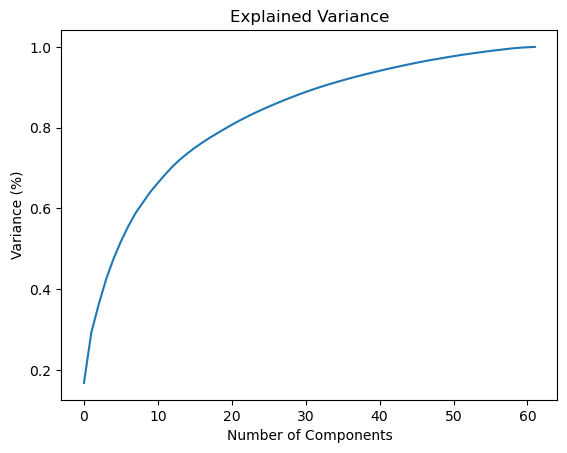

In [78]:
plt.figure()
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Variance (%)') #for each component
plt.title('Explained Variance')
plt.show()

### How many components should we keep?

There is no single correct number for every problem. A common rule is to look at how many components are needed to retain a target such as 90% or 95% of the variance.

The code below calculates the **first component count that reaches each target**. This avoids a common off-by-one mistake when using `np.where`, whose returned indices start at zero.

In [83]:
np.where(np.cumsum(pca.explained_variance_ratio_)>0.9)

(array([32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48,
        49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61], dtype=int64),)

In [85]:
np.where(np.cumsum(pca.explained_variance_ratio_)>0.95)

(array([43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59,
        60, 61], dtype=int64),)

From the diagram and code above, it can be seen that 32 principal components explain almost 90% of the variance in data and 43 principal components explain around 95% of the variance in data.

So, instead of giving all the columns as input, we’d only feed these 32 or 43 principal components of the data to the machine learning algorithm and we’d obtain a similar result.

In [88]:
pca = PCA(n_components=43)
new_data = pca.fit_transform(df)
# This will be the new data fed to the algorithm.
# Number of columns
num_components = 43

# Column names pattern
column_names = [f'principal component {i}' for i in range(1, num_components + 1)]

# Create DataFrame
principal_Df = pd.DataFrame(data=new_data, columns=column_names)


In [90]:
principal_Df.head()

,principal component 1,principal component 2,principal component 3,principal component 4,principal component 5,principal component 6,principal component 7,principal component 8,principal component 9,principal component 10,...,principal component 34,principal component 35,principal component 36,principal component 37,principal component 38,principal component 39,principal component 40,principal component 41,principal component 42,principal component 43
0,1.655937,0.779447,-2.377400,-4.888855,-0.977575,1.336602,3.590963,-0.588800,-1.716008,0.163731,...,-0.145965,-0.309988,1.498823,0.845610,-0.122212,0.192183,0.582400,-0.142089,-0.730332,0.308359
1,2.323247,-1.007189,-1.814792,-4.435043,3.095036,-0.082943,2.028901,-1.490401,-1.470771,-2.798729,...,1.000011,-0.189043,0.296895,0.439913,0.650837,0.677532,-0.530166,-0.381122,0.645609,0.505905
2,0.301161,-2.715173,-1.138535,-1.573979,1.513119,0.544081,0.665594,-1.687164,1.107657,-2.317461,...,0.444731,-0.213572,-0.390190,-0.380531,1.091226,0.993919,0.874349,-1.064820,0.070750,-0.734273
3,0.331745,-3.560087,-0.423917,0.930106,2.305437,-1.585218,0.319676,-0.136145,0.412278,-0.595822,...,0.700256,1.001873,-0.248500,-0.325596,0.032225,-0.580527,-0.144230,-0.530396,-0.888729,0.529660
4,4.155373,-2.724240,2.273338,0.803203,1.810133,-0.361164,-1.425360,-0.202324,0.941189,-0.100334,...,-0.734611,-0.410204,-0.211578,-0.192900,0.044627,0.800354,0.417591,-0.843012,0.162615,0.533186


* Here, we see that earlier we had 62 columns in the data earlier. Now with the help of Scree plot and PCA, we have reduced the number of      features to be used for model building to 43. This is the advantage of PCA. _It drastically reduces the number of features, thereby           considerably reducing the training time for the model._

**Pros of PCA:**

- Correlated features are removed.
- Model training time is reduced.
- Overfitting is reduced.
- Helps in better visualizations
- Ability to handle noise

**Cons of PCA**
- The resultant principal components are less interpretable than the original data
- Can lead to information loss if the explained variance threshold is not considered appropriately.



### Conclusion
From all the explanations above, we can conclude that PCA is a very powerful technique for reducing the dimensions of the data, projecting the data from a higher dimension to a lower dimension, helps in data visualization, helps in data compression and most of all increases the model training speed drastically by decreasing the number of variables involved in computation.